# Fig. 6a: sorting accuracy of ground truth neurons

**author**: laquitainesteeve@gmail.com

**purpose**: for each simulation (S: Buccino synthetic, NS: biophysical spontaneous, E: biophysical evoked at 40 kHz, DS: biophysical dense probe, pooled over three depths) and each spike sorter, ground truth neurons ranked by their sorting accuracy, with the proportion of neurons sorted with above 80% accuracy. Source data and svg are saved in figures/8_source_data/fig6a/.

**method**
* first 10 minutes; ground truth neurons are within 50 microns of the contacts
* a ground truth neuron's accuracy is its best agreement score (delta_time = 1.3 ms) with a sorted unit; the sorted units are the "good" units for the Kilosort family and all units for Kilosort and Herdingspikes

**data**: see fig6b.ipynb. D1 sortings come from dataset/01_intermediate/sorting/dense_probe1 (the DANDI depth-1 sortings are identical to depth 2).

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)

# custom package
from src.nodes.analysis.accuracy import accuracy as acc

# PARAMETERS
DT = 1.3          # ms (optimized)
THR = 0.8         # "good" unit threshold
SORTERS = ["ks4", "ks3", "ks2.5", "ks2", "ks", "hs"]

# DATASETS: ground truth and sortings (KS4, KS3, KS2.5, KS2, KS, HS)
SORTING = "dataset/01_intermediate/sorting/"
RAW = "dataset/00_raw/"
def sortings(folder):
    return [f"{SORTING}{folder}/Sorting{s}_10m" for s in ["KS4", "KS3", "KS2_5", "KS2", "KS", "HS"]]

DATASETS = {
    # Neuropixels
    "S":  dict(probe="Neuropixels", gt=RAW + "sorting_buccino", sorting=sortings("buccino")),
    "NS": dict(probe="Neuropixels", gt=RAW + "ground_truth_npx_spont", sorting=sortings("npx_spont")),
    "E":  dict(probe="Neuropixels", gt=RAW + "ground_truth_npx_evoked_40khz_10m", sorting=sortings("npx_evoked_40khz")),
    # dense probe (3 depths)
    "D1": dict(probe="dense", gt=RAW + "ground_truth_dense_probe1", sorting=sortings("dense_probe1")),
    "D2": dict(probe="dense", gt=RAW + "ground_truth_dense_probe2", sorting=sortings("dense_probe2")),
    "D3": dict(probe="dense", gt=RAW + "ground_truth_dense_probe3", sorting=sortings("dense_probe3")),
}

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Calculate the accuracy of each ground truth neuron

In [2]:
%%time

# accuracy[dataset]: sorters (rows) x ground truth neurons (columns), best agreement score
accuracy = {}
for name, d in DATASETS.items():
    accuracy[name] = acc.get_accuracy(*d["sorting"], d["gt"], DT)
    print(name, "ground truth neurons:", accuracy[name].shape[1])

S ground truth neurons: 250


NS ground truth neurons: 1388


E ground truth neurons: 1552


D1 ground truth neurons: 287


D2 ground truth neurons: 770


D3 ground truth neurons: 1123
CPU times: user 11.8 s, sys: 199 ms, total: 12 s
Wall time: 12 s


## Source data: ground truth neurons ranked by accuracy, per sorter and simulation

In [3]:
# simulations: the dense probe is pooled over its three depths, and neurons are ranked per sorter
panels = {
    "S": accuracy["S"],
    "NS": accuracy["NS"],
    "E": accuracy["E"],
    "DS": np.hstack([accuracy["D1"], accuracy["D2"], accuracy["D3"]]),
}
rows = []
for name, a in panels.items():
    for ix, sorter in enumerate(SORTERS):
        ranked = np.sort(a[ix, :])[::-1]
        rows.append(pd.DataFrame({"simulation": name, "sorter": sorter, "rank": np.arange(1, len(ranked) + 1), "accuracy": ranked}))
df = pd.concat(rows, ignore_index=True)
display(df.groupby(["simulation", "sorter"], sort=False).agg(n_neurons=("accuracy", "size"), n_above_80=("accuracy", lambda x: int((x >= THR).sum()))).T)

simulation    S                              NS                    ...     E  \
sorter      ks4  ks3 ks2.5  ks2   ks   hs   ks4   ks3 ks2.5   ks2  ... ks2.5   
n_neurons   250  250   250  250  250  250  1388  1388  1388  1388  ...  1552   
n_above_80  224  214   244  247  187  124    79    56   190   198  ...   115   

simulation                      DS                                
sorter       ks2    ks    hs   ks4   ks3 ks2.5   ks2    ks    hs  
n_neurons   1552  1552  1552  2180  2180  2180  2180  2180  2180  
n_above_80   120   223    80    35    23    96    98   124    35  

[2 rows x 24 columns]

In [4]:
TITLES = {"S": "Synthetic\n(n={n:,} model neurons)", "NS": "Biophy. Spont\n(n={n:,})", "E": "Biophy. Evoked\n(n={n:,})", "DS": "Biophy. Spont\n(n={n:,})"}
XTICKS = {"S": [0, 200], "NS": [0, 1000], "E": [0, 1000], "DS": [0, 2000]}

def plot_source_data(df: pd.DataFrame):
    """Ground truth neurons ranked by sorting accuracy, per simulation (panel) and sorter (color)"""

    fig, ax = plt.subplots(1, 4, figsize=(4.2, 2.1))
    plt.subplots_adjust(left=0.12, right=0.99, top=0.68, bottom=0.2, wspace=0.12)
    for a, name in zip(ax, ["S", "NS", "E", "DS"]):
        d = df[df["simulation"] == name]
        n = d[d["sorter"] == SORTERS[0]].shape[0]
        for ix, sorter in enumerate(SORTERS):
            ds = d[d["sorter"] == sorter]
            a.plot(ds["rank"] - 1, ds["accuracy"], "-", color=COLORS[ix], linewidth=1.2, label=sorter)
            # proportion of neurons sorted with above 80% accuracy
            p = (ds["accuracy"] >= THR).mean()
            if name == "S":   # labelled, below the threshold, left
                a.text(0.1, 0.62 - 0.105 * ix, f"{sorter}: {round(p, 2):g}", transform=a.get_yaxis_transform(), ha="left", va="center", fontsize=6)
            else:             # column of proportions, same order as the legend
                a.text(0.8, 1.0 - 0.105 * ix, f"{p:.2f}", transform=a.get_yaxis_transform(), ha="center", va="center", fontsize=6)
        a.axhline(y=THR, color="r", linestyle="--", linewidth=0.7)
        a.set_title(TITLES[name].format(n=n), fontsize=6, pad=3)
        a.set_xlim(left=0); a.set_ylim(0, 1.03)
        a.set_xticks(XTICKS[name])
        a.spines[["right", "top"]].set_visible(False)
        a.spines["bottom"].set_position(("axes", -0.05))
        a.spines["left"].set_position(("axes", -0.05))
        if name == "S":
            a.set_yticks([0, 0.25, 0.5, 0.75, 1.0]); a.set_yticklabels(["0.00", "0.25", "0.50", "0.75", "1.00"])
            a.text(0.0, THR + 0.02, "0.80", color="crimson", transform=a.get_yaxis_transform(), ha="left", va="bottom", fontsize=6.5)
        else:
            a.set_yticks([]); a.spines["left"].set_visible(False)
    ax[0].set_ylabel("Sorting accuracy (ratio)")
    fig.text((ax[1].get_position().x0 + ax[2].get_position().x1) / 2, 0.03, "True units ranked by sorting accuracy", ha="center", va="bottom")

    # group titles
    top = ax[1].get_position().y1 + 0.17
    fig.text((ax[1].get_position().x0 + ax[2].get_position().x1) / 2, top, "Neuropixels (NPX)", ha="center", va="bottom", fontweight="bold", fontsize=6.5)
    fig.text((ax[3].get_position().x0 + ax[3].get_position().x1) / 2, top, "Dense probe", ha="center", va="bottom", fontweight="bold", fontsize=6.5)

    # legend (left) and figure title (right)
    handles, labels = ax[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower left", ncol=6, frameon=False, handlelength=1.1, handletextpad=0.3, columnspacing=0.7,
               bbox_to_anchor=(0.02, top + 0.085), fontsize=6.5)
    fig.text(0.99, top + 0.1, "Spike sorting accuracy on ground truths", ha="right", va="bottom", fontweight="bold", fontsize=6.5)
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 1.31 s, sys: 20 ms, total: 1.33 s
Wall time: 1.33 s


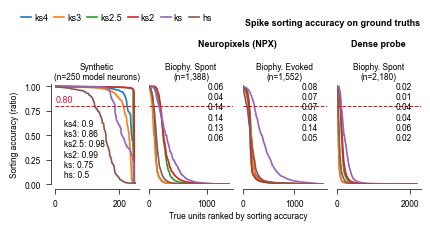

In [5]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig6a", exist_ok=True)
plt.savefig("figures/8_source_data/fig6a/fig6a.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig6a/fig6a.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 734 ms, sys: 2 ms, total: 736 ms
Wall time: 735 ms


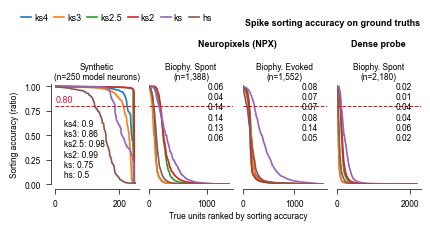

In [6]:
%%time

df = pd.read_excel("figures/8_source_data/fig6a/fig6a.xlsx")
fig, ax = plot_source_data(df)